# **TRAVEL INSURANCE PURCHASE PREDICTION**

## **Business Problem**

**1. Context** 

Many companies selling tickets or travel packages, give consumers the option to purchase travel insurance, also known as travelers insurance. Some travel policies cover damage to personal property, rented equipment, such as rental cars, or even the cost of paying a ransom. 
Frequently sold as a package, travel insurance may include several types of coverage. The main categories of travel insurance include trip cancellation or interruption coverage, baggage and personal effects coverage, medical expense coverage, and accidental death or flight accident coverage.
Coverage often includes 24/7 emergency services, such as replacing lost passports, cash wire assistance, and re-booking canceled flights. Also, some travel insurance policies may duplicate existing coverage from other providers or offer protection for costs that are refundable by other means. 

[https://www.investopedia.com/terms/t/travel-insurance.asp#:~:text=Travel%20insurance%20is%20a%20type,those%20traveling%20domestically%20or%20abroad.]


**2. Problem Statement**

So far, tour & travel companies offer travel insurance to all their customers manually. This method is not efficient in terms of time and cost because they have to contact the customers one by one.
Therefore, a more efficient method is needed so that the companies can only contact customers who are most likely to buy travel insurance.

A tour & travels company in India want to offer travel insurance package to their customers. 
The new insurance package also includes covid cover. 
The insurance was offered to some of the customers in 2019 and the given data has been extracted 
from the performance/sales of the package during that period.
The company requires to know the which customers would be interested to buy it based on its database history. 

The data is provided for almost 2000 of its previous customers and 
The company want to build an ML model that can predict if the customer will be interested 
to buy the travel insurance package based on certain parameters given below.
We act as a data scientist in this travel company.

**3. Goal**

To classify customers wether they will purchase travel insurance or not.


**4. Analytic Approach**

We will do exploratory data analysis to understand the data and some pattern it has. 
After that, we will build a classification ML model to predict wether a customer will buy travel insurance or not.


**5. Metric Evaluation**

We will use f1 score because we intersted in False Negative and False Positive in positive class.
- False Negative (FN): if a customer is predicted not to buy travel insurance, but he/she actually did. 
- False Positive (FP): if a customer is predicted to buy travel insurance, but he/she actually did not. 

FN cost: we lost a prospect customer. In the other hand, 

FP cost: we waste our money and time to offer non-prospect customer.

## **Data Understanding**

Features

- Age: age of the customer
- Employment type: the sector in which customer is employed
- Graduateornot: whether the customer is college graduate or not
- Annualincome: the yearly income of the customer in indian rupees [rounded to nearest 50 thousand rupees]
- Familymembers: number of members in customer's family
- Chronicdisease: whether the customer suffers from any major disease or conditions like diabetes/high bp or asthama,etc.
- Frequentflyer: derived data based on customer's history of booking air tickets on atleast 4 different instances in the last 2 years[2017:2019].
- Evertravelledabroad: has the customer ever travelled to a foreign country[not necessarily using the company's services]

Target 

- Travelinsurance: did the customer buy travel insurance package during introductory offering held in the year 2019.


## **Dataset**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import category_encoders as ce
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV, train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, f1_score
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, confusion_matrix, recall_score, fbeta_score, make_scorer

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost.sklearn import XGBClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# from imblearn.over_sampling import RandomOverSampler, SMOTE
# from imblearn.under_sampling import RandomUnderSampler, NearMiss
# from imblearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('TravelInsurancePrediction.csv')
df.rename(columns={"Unnamed: 0" :'ID'}, inplace=True)
df

,ID,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,0,31,Government Sector,Yes,400000,6,1,No,No,0
1,1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1
3,3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0
4,4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0
...,...,...,...,...,...,...,...,...,...,...
1982,1982,33,Private Sector/Self Employed,Yes,1500000,4,0,Yes,Yes,1
1983,1983,28,Private Sector/Self Employed,Yes,1750000,5,1,No,Yes,0
1984,1984,28,Private Sector/Self Employed,Yes,1150000,6,1,No,No,0
1985,1985,34,Private Sector/Self Employed,Yes,1000000,6,0,Yes,Yes,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1987 entries, 0 to 1986
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   1987 non-null   int64 
 1   Age                  1987 non-null   int64 
 2   Employment Type      1987 non-null   object
 3   GraduateOrNot        1987 non-null   object
 4   AnnualIncome         1987 non-null   int64 
 5   FamilyMembers        1987 non-null   int64 
 6   ChronicDiseases      1987 non-null   int64 
 7   FrequentFlyer        1987 non-null   object
 8   EverTravelledAbroad  1987 non-null   object
 9   TravelInsurance      1987 non-null   int64 
dtypes: int64(6), object(4)
memory usage: 155.4+ KB


In [4]:
df.duplicated().sum()

0

In [5]:
# Estimation of non-duplicated data

df.drop('ID', axis=1).drop_duplicates().shape

(1249, 9)

Decide to not remove duplicate, as replacement of NOT DOING the resampling. 

In [6]:
df

,ID,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,0,31,Government Sector,Yes,400000,6,1,No,No,0
1,1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1
3,3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0
4,4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0
...,...,...,...,...,...,...,...,...,...,...
1982,1982,33,Private Sector/Self Employed,Yes,1500000,4,0,Yes,Yes,1
1983,1983,28,Private Sector/Self Employed,Yes,1750000,5,1,No,Yes,0
1984,1984,28,Private Sector/Self Employed,Yes,1150000,6,1,No,No,0
1985,1985,34,Private Sector/Self Employed,Yes,1000000,6,0,Yes,Yes,1


In [7]:
df.isna().sum()

ID                     0
Age                    0
Employment Type        0
GraduateOrNot          0
AnnualIncome           0
FamilyMembers          0
ChronicDiseases        0
FrequentFlyer          0
EverTravelledAbroad    0
TravelInsurance        0
dtype: int64

In [8]:
df.loc[:,~df.columns.isin(['ID'])].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1987.0,29.650226,2.913308,25.0,28.0,29.0,32.0,35.0
AnnualIncome,1987.0,932762.959235,376855.684748,300000.0,600000.0,900000.0,1250000.0,1800000.0
FamilyMembers,1987.0,4.752894,1.609650,2.0,4.0,5.0,6.0,9.0
ChronicDiseases,1987.0,0.277806,0.448030,0.0,0.0,0.0,1.0,1.0
TravelInsurance,1987.0,0.357323,0.479332,0.0,0.0,0.0,1.0,1.0


In [9]:
df.loc[:,~df.columns.isin(['ID'])].describe(include="object").T

,count,unique,top,freq
Employment Type,1987,2,Private Sector/Self Employed,1417
GraduateOrNot,1987,2,Yes,1692
FrequentFlyer,1987,2,No,1570
EverTravelledAbroad,1987,2,No,1607


# EDA

We're going to compare the average of each numerical features, to our target

In [10]:
np.__version__

'1.23.5'

## Numerical

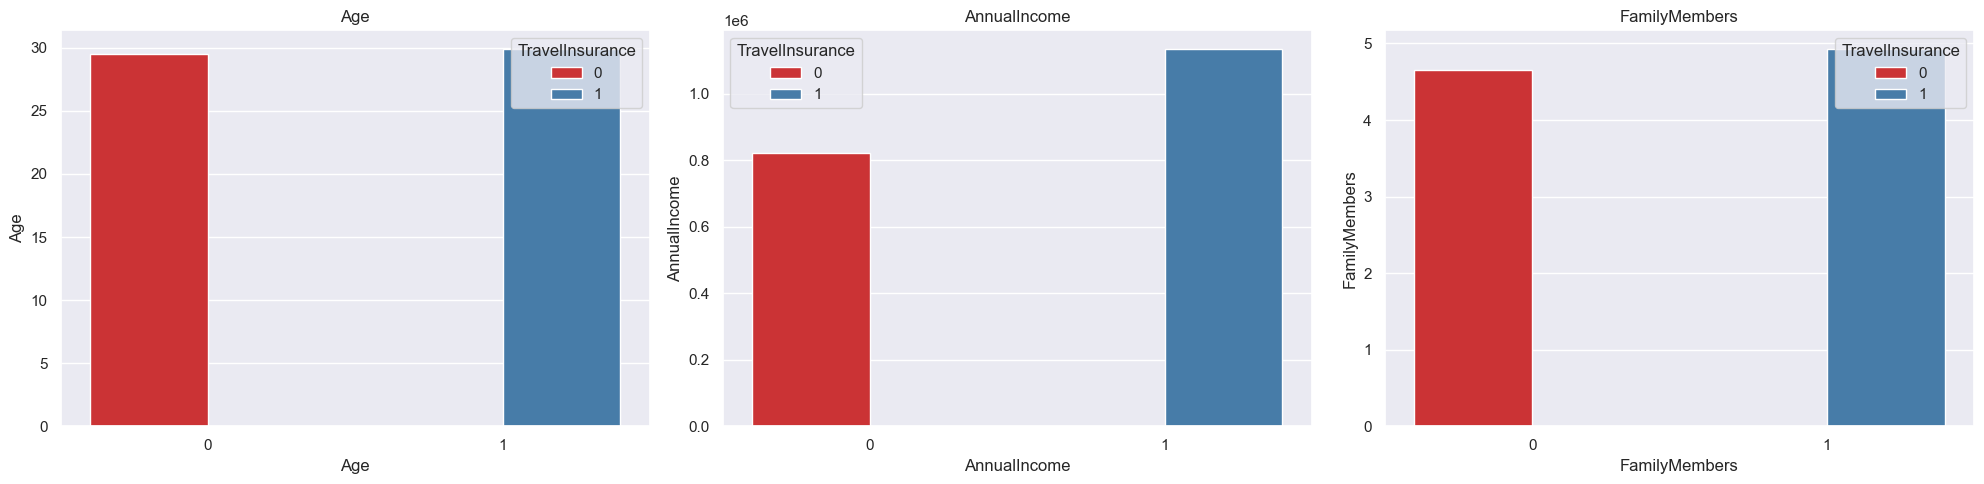

In [11]:
features = ['Age', 'AnnualIncome', 'FamilyMembers'] 

plt.figure(figsize=(20,5))
sns.set(palette='Set1')
plotnumber = 1

for feature in features:
    ax = plt.subplot(1,3,plotnumber)
    sns.barplot(data = df, x='TravelInsurance', y=feature, hue='TravelInsurance', errorbar=None)
    plt.xlabel(feature)
    plt.title(feature)
    plotnumber+=1
    plt.tight_layout()


In [12]:
df.groupby('TravelInsurance')[['Age', 'AnnualIncome', 'FamilyMembers']].mean()

,Age,AnnualIncome,FamilyMembers
TravelInsurance,,,
0,29.517619,8.212999e+05,4.657009
1,29.888732,1.133239e+06,4.925352


Age  
* People who buy and don't buy the travel insurance, have similar average of age (29.5 years old).  

Annual Income 
* People who buy travel insurance have more income (1,133k) than the people who don't (821k).  

Family Members 
* People who buy travel insurance have more family members than the people who don't.

## Categorical

In [13]:
df.columns

Index(['ID', 'Age', 'Employment Type', 'GraduateOrNot', 'AnnualIncome',
       'FamilyMembers', 'ChronicDiseases', 'FrequentFlyer',
       'EverTravelledAbroad', 'TravelInsurance'],
      dtype='object')

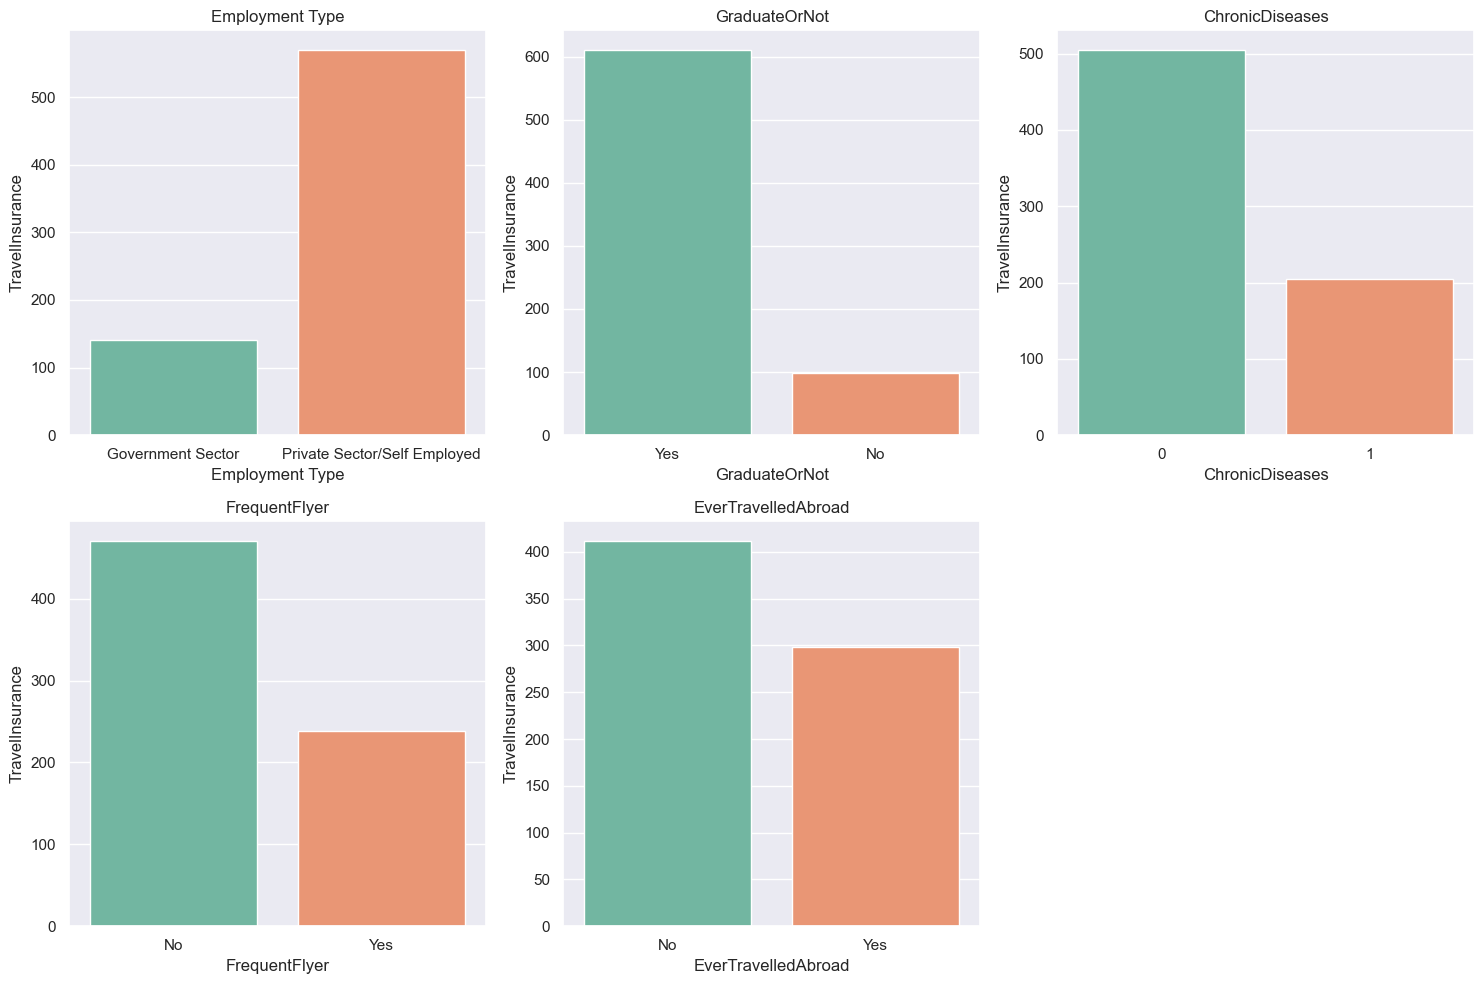

In [14]:
features = ['Employment Type', 'GraduateOrNot', 'ChronicDiseases', 'FrequentFlyer', 'EverTravelledAbroad']

# Calculate only positive value
plt.figure(figsize=(15,10))
sns.set(palette='Set2')
plotnumber = 1

for feature in features:
    ax = plt.subplot(2,3,plotnumber)
    sns.barplot(data = df, x=feature, y='TravelInsurance', estimator=np.sum, errorbar=None)
    plt.xlabel(feature)
    plt.title(feature)
    plotnumber+=1
    plt.tight_layout()

More people who buy travel insurance are in this Category:  
* Private Sector/ Self Employed 
* Graduated  
* No frequent flyer  
* Never travelled abroad
* No chronic disease 

In [15]:
def create_pivot(feature):
    df_pivot = df.pivot_table(
        index = 'TravelInsurance', # our target
        columns = feature,
        values = 'ID',
        aggfunc = len
    )

    df_pivot.loc['Total'] = df_pivot.sum()
    df_pivot.loc['%'] = round((df_pivot.loc[1]/df_pivot.loc['Total'])*100, 1)

    return df_pivot.T.sort_values('%', ascending=False)

In [16]:
create_pivot('Employment Type')

TravelInsurance,0,1,Total,%
Employment Type,,,,
Private Sector/Self Employed,847.0,570.0,1417.0,40.2
Government Sector,430.0,140.0,570.0,24.6


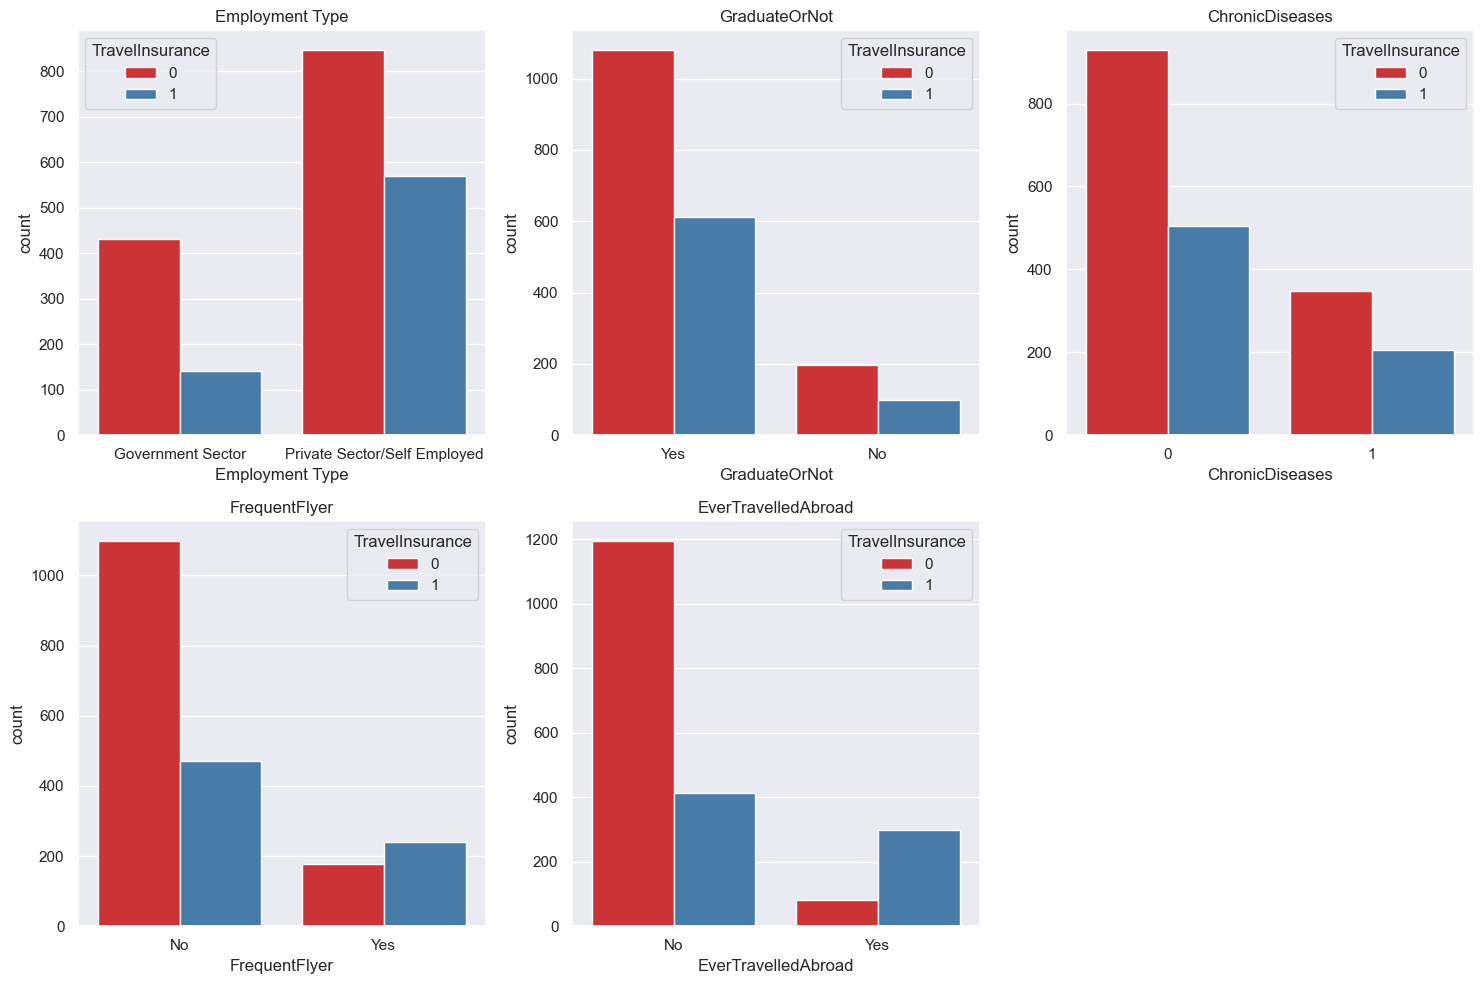

In [17]:
# Categorical Analysis (2)

features = ['Employment Type', 'GraduateOrNot', 'ChronicDiseases', 'FrequentFlyer', 'EverTravelledAbroad']

plt.figure(figsize=(15,10))
sns.set(palette='Set1')
plotnumber = 1

for feature in features:
    ax = plt.subplot(2,3,plotnumber)
    # sns.barplot(data = df, x=feature, y='TravelInsurance', estimator=np.sum, errorbar=None)
    sns.countplot(data=df, x=feature, hue='TravelInsurance')
    plt.xlabel(feature)
    plt.title(feature)
    plotnumber+=1
    plt.tight_layout()

Employment Type 
* More people work in Private Sector/Self Employed than in Government sector, so does for buy and don't buy travel insurance.  

Graduate  
* The total of graduated people are bigger than those who not graduated, so does for buy and don't buy travel insurance.

Frequent flyer  
* More people who don't fly frequently than who frequently fly. 
* But, the frequent flyer is more likely buy travel insurance than people who are not frequent flyer.
* More people buy travel insurance than who buy when they don't fly frequently. 

Ever Traveled Abrod 
* More people never traveled abroad than have traveled abroad. 
* People who ever traveled abroad is more likely to buy travel insurance. 
* More people buy travel insurance than who buy when they never traveled abroad. 

Chronic Disease 
* Whether or not they have chronic disease, they don't buy travel insurance


# Data Splitting 

In [18]:
X = df.drop(columns=['TravelInsurance', 'ID'])
y = df['TravelInsurance']

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=0)

# Data Preprocessing

In [20]:
transformer = ColumnTransformer([
    ('onehot', OneHotEncoder(), ['Employment Type', 'GraduateOrNot', 'FrequentFlyer', 'EverTravelledAbroad'])], 
    remainder='passthrough')

# Scaler 
scaler = StandardScaler()

In [21]:
transformer.fit_transform(X_train)

array([[1.00e+00, 0.00e+00, 0.00e+00, ..., 4.00e+05, 5.00e+00, 1.00e+00],
       [1.00e+00, 0.00e+00, 0.00e+00, ..., 1.05e+06, 7.00e+00, 0.00e+00],
       [0.00e+00, 1.00e+00, 0.00e+00, ..., 1.40e+06, 7.00e+00, 0.00e+00],
       ...,
       [0.00e+00, 1.00e+00, 0.00e+00, ..., 8.00e+05, 6.00e+00, 0.00e+00],
       [1.00e+00, 0.00e+00, 0.00e+00, ..., 6.00e+05, 5.00e+00, 0.00e+00],
       [0.00e+00, 1.00e+00, 0.00e+00, ..., 1.05e+06, 8.00e+00, 0.00e+00]])

In [22]:
transformer.get_feature_names_out()

array(['onehot__Employment Type_Government Sector',
       'onehot__Employment Type_Private Sector/Self Employed',
       'onehot__GraduateOrNot_No', 'onehot__GraduateOrNot_Yes',
       'onehot__FrequentFlyer_No', 'onehot__FrequentFlyer_Yes',
       'onehot__EverTravelledAbroad_No',
       'onehot__EverTravelledAbroad_Yes', 'remainder__Age',
       'remainder__AnnualIncome', 'remainder__FamilyMembers',
       'remainder__ChronicDiseases'], dtype=object)

In [23]:
features = list(transformer.get_feature_names_out())

list_features = []

for feature in features:
    list_features.append('_'.join(feature.split('_')[2:]))

list_features

['Employment Type_Government Sector',
 'Employment Type_Private Sector/Self Employed',
 'GraduateOrNot_No',
 'GraduateOrNot_Yes',
 'FrequentFlyer_No',
 'FrequentFlyer_Yes',
 'EverTravelledAbroad_No',
 'EverTravelledAbroad_Yes',
 'Age',
 'AnnualIncome',
 'FamilyMembers',
 'ChronicDiseases']

# Benchmark Modeling

In [24]:
logreg = LogisticRegression()
knn = KNeighborsClassifier()
tree = DecisionTreeClassifier(random_state=0)
rf = RandomForestClassifier(random_state=0)
ada = AdaBoostClassifier(random_state=0)
gbc = GradientBoostingClassifier(random_state=0)
xgbc = XGBClassifier(random_state=0, verbosity=0)

In [25]:
# Check benchmark model 

models = [logreg, knn, tree, rf, ada, gbc, xgbc]
model_name = []

score = []
train_score = []
std_value = []

for i in models:
    skfold = StratifiedKFold(n_splits=5)
    estimator = Pipeline([
        ('transformer', transformer),
        ('scaler', scaler),
        ('model name', i)
    ])

    model_cv = cross_val_score(estimator, X_train, y_train, cv=skfold, scoring='f1', error_score='raise')

    print(i, model_cv)
    score.append(model_cv)
    train_score.append(model_cv.mean())
    std_value.append(model_cv.std())
    model_name.append(i.__class__.__name__)

LogisticRegression() [0.58888889 0.61290323 0.6        0.58638743 0.58695652]
KNeighborsClassifier() [0.66990291 0.62886598 0.70935961 0.64646465 0.63768116]
DecisionTreeClassifier(random_state=0) [0.68122271 0.63849765 0.66981132 0.64788732 0.62857143]
RandomForestClassifier(random_state=0) [0.71232877 0.65714286 0.68269231 0.6635514  0.67326733]
AdaBoostClassifier(random_state=0) [0.69945355 0.67032967 0.65142857 0.64088398 0.64      ]
GradientBoostingClassifier(random_state=0) [0.73958333 0.66666667 0.73015873 0.67379679 0.71657754]
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None

In [ ]:
benchmark_model_train = pd.DataFrame({
    'model' : model_name,
    'trainscore' : train_score,
    'std' : std_value
}).sort_values(by='trainscore', ascending=False)

benchmark_model_train

,model,trainscore,std
5,GradientBoostingClassifier,0.705357,0.029683
3,RandomForestClassifier,0.677797,0.019321
6,XGBClassifier,0.676672,0.023537
4,AdaBoostClassifier,0.660419,0.022366
1,KNeighborsClassifier,0.658455,0.028890
2,DecisionTreeClassifier,0.653198,0.019556
0,LogisticRegression,0.595027,0.010215


In [27]:
test_score = []
model_name = [] 

for i in models:
    model_pipeline = Pipeline([
        ('transformer', transformer),
        ('scaler', scaler),
        ('model name', i)
    ])

    model_pipeline.fit(X_train, y_train)
    y_pred_test = model_pipeline.predict(X_test)

    f1= f1_score(y_test, y_pred_test)
    test_score.append(f1)
    model_name.append(i.__class__.__name__)

In [28]:
benchmark_model_test = pd.DataFrame({
    'model' : model_name,
    'testscore' : test_score
}).sort_values(by='testscore', ascending=False)

benchmark_model_test

,model,testscore
5,GradientBoostingClassifier,0.739130
4,AdaBoostClassifier,0.705357
2,DecisionTreeClassifier,0.696970
3,RandomForestClassifier,0.692308
6,XGBClassifier,0.682731
1,KNeighborsClassifier,0.674699
0,LogisticRegression,0.624473


In [29]:
# Combine and Compare 

benchmark_model = benchmark_model_test.set_index('model').join(benchmark_model_train.set_index('model'))
benchmark_model.drop('std', axis=1, inplace=True)
benchmark_model['diff'] = benchmark_model['testscore'] - benchmark_model['trainscore']
benchmark_model['diff'] = benchmark_model['diff'].agg('abs')
benchmark_model.sort_values(by='testscore', ascending=False)


,testscore,trainscore,diff
model,,,
GradientBoostingClassifier,0.739130,0.705357,0.033774
AdaBoostClassifier,0.705357,0.660419,0.044938
DecisionTreeClassifier,0.696970,0.653198,0.043772
RandomForestClassifier,0.692308,0.677797,0.014511
XGBClassifier,0.682731,0.676672,0.006059
KNeighborsClassifier,0.674699,0.658455,0.016244
LogisticRegression,0.624473,0.595027,0.029445


**Benchmark Model on Score : Gradient Boosting Classifier**  
**Benchmark Model on Stability : XGB Cassifier**


# Hyperparameter Tuning 

**Gradient Boosting**

In [30]:
# Depth of tree
max_depth = list(np.arange(1,10))

# Learning rate
learning_rate = list(np.arange(1,100)/100)

# Number of tree
n_estimator = list(np.arange(50,500))

# Number of train set in each tree 
subsample = list(np.arange(2,10)/10)

# Number of features used for splitting 
max_features = list(np.arange(1,10)/10)

# Hyperparameter GBC 
hyperparameter_space_gbc = {
    'model__max_depth':max_depth,
    'model__learning_rate':learning_rate,
    'model__n_estimators':n_estimator,
    'model__subsample':subsample,
    'model__max_features':max_features
}

In [31]:
# Stratified kfold
skf = StratifiedKFold(n_splits=5)

# Benchmark model 1 
gbc = GradientBoostingClassifier(random_state=0)

# Create algorithm chain 
estimator_gbc = Pipeline([
    ('transformer', transformer),
    ('model', gbc)
])

# Hyperparameter tuning 
random_gbc = RandomizedSearchCV(estimator= estimator_gbc, 
                                param_distributions=hyperparameter_space_gbc, 
                                cv=skf, 
                                scoring='f1', 
                                n_jobs=-1, 
                                n_iter=20, 
                                random_state=0)

In [32]:
random_gbc.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
                   estimator=Pipeline(steps=[('transformer',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('onehot',
                                                                               OneHotEncoder(),
                                                                               ['Employment '
                                                                                'Type',
                                                                                'GraduateOrNot',
                                                                                'FrequentFlyer',
                                                                                'EverTravelledAbroad'])])),
                                             ('model',
                                              GradientBoostingClassifier(random_state=0))]),
                   n_iter=20, n...
                                                                 0.21, 0.22,
                                                                 0.23, 0.24,
                                                                 0.25, 0.26,
                                                                 0.27, 0.28,
                                                                 0.29, 0.3, ...],
                                        'model__max_depth': [1, 2, 3, 4, 5, 6,
                                                             7, 8, 9],
                                        'model__max_features': [0.1, 0.2, 0.3,
                                                                0.4, 0.5, 0.6,
                                                                0.7, 0.8, 0.9],
                                        'model__n_estimators': [50, 51, 52, 53,
                                                                54, 55, 56, 57,
                                                                58, 59, 60, 61,
                                                                62, 63, 64, 65,
                                                                66, 67, 68, 69,
                                                                70, 71, 72, 73,
                                                                74, 75, 76, 77,
                                                                78, 79, ...],
                                        'model__subsample': [0.2, 0.3, 0.4, 0.5,
                                                             0.6, 0.7, 0.8,
                                                             0.9]},
                   random_state=0, scoring='f1')

In [33]:
pd.DataFrame(random_gbc.cv_results_).sort_values(by='rank_test_score', ascending=False)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__subsample,param_model__n_estimators,param_model__max_features,param_model__max_depth,param_model__learning_rate,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
9,1.061936,0.035531,0.014004,0.001670,0.7,184,0.5,6,0.78,"{'model__subsample': 0.7, 'model__n_estimators...",0.356846,0.519481,0.560345,0.419048,0.374502,0.446044,0.080325,20
1,2.601136,0.488691,0.022327,0.004237,0.7,352,0.6,6,0.63,"{'model__subsample': 0.7, 'model__n_estimators...",0.456026,0.503937,0.360000,0.496403,0.418410,0.446955,0.053198,19
8,1.109693,0.034065,0.019175,0.005745,0.5,94,0.3,9,0.94,"{'model__subsample': 0.5, 'model__n_estimators...",0.253968,0.476923,0.473118,0.546763,0.542373,0.458629,0.106968,18
14,2.148180,0.089165,0.029523,0.006212,0.2,269,0.5,8,0.3,"{'model__subsample': 0.2, 'model__n_estimators...",0.520270,0.435088,0.344828,0.504065,0.527473,0.466345,0.069008,17
5,1.555271,0.105094,0.018125,0.001666,0.5,202,0.6,7,0.86,"{'model__subsample': 0.5, 'model__n_estimators...",0.472492,0.526316,0.514925,0.508475,0.489451,0.502332,0.019120,16
19,1.626991,0.072287,0.016841,0.005364,0.9,480,0.4,4,0.81,"{'model__subsample': 0.9, 'model__n_estimators...",0.396313,0.552995,0.614719,0.522523,0.444444,0.506199,0.077616,15
4,0.577992,0.142091,0.011868,0.004290,0.5,211,0.2,1,0.95,"{'model__subsample': 0.5, 'model__n_estimators...",0.670391,0.615385,0.602273,0.638743,0.640449,0.633448,0.023410,14
15,0.491058,0.022213,0.013177,0.001742,0.2,215,0.3,2,0.41,"{'model__subsample': 0.2, 'model__n_estimators...",0.582160,0.643902,0.666667,0.675926,0.683417,0.650414,0.036620,13
12,4.240008,0.083541,0.027059,0.004716,0.9,472,0.4,7,0.1,"{'model__subsample': 0.9, 'model__n_estimators...",0.687500,0.638889,0.666667,0.654545,0.643902,0.658301,0.017440,12
6,2.218185,0.026256,0.018702,0.002901,0.9,380,0.2,6,0.52,"{'model__subsample': 0.9, 'model__n_estimators...",0.681818,0.675799,0.675926,0.615385,0.644231,0.658632,0.025334,11


In [34]:
print("Gradient Boosting Classifier")
print("Best Score : ", random_gbc.best_score_)
print("Best Params : ", random_gbc.best_params_)

Gradient Boosting Classifier
Best Score :  0.709606567487097
Best Params :  {'model__subsample': 0.6, 'model__n_estimators': 70, 'model__max_features': 0.6, 'model__max_depth': 3, 'model__learning_rate': 0.02}


In [35]:
# Depth of tree
max_depth = list(np.arange(1,10))

# Learning rate
learning_rate = list(np.arange(1,100)/100)

# Number of tree
n_estimators = list(np.arange(50,500,50))

# Number of train set in each tree 
subsample = list(np.arange(2,10)/10)

# Gamma means the minimum impurity will be decreased
gamma = list(np.arange(1,11))

# Number of feature used for each tree
colsample_bytree = list(np.arange(1,10)/10)

# Regularization
reg_alpha = list(np.logspace(-3,1,10))

# Hyperparameter XGB
hyperparameter_space_xgb = {
    'model__max_depth':max_depth,
    'model__learning_rate':learning_rate,
    'model__n_estimators':n_estimators,
    'model__subsample':subsample,
    'model__gamma':gamma,
    'model__colsample_bytree' : colsample_bytree,
    'model__reg_alpha' : reg_alpha
}

In [36]:
# Benchmark model 2
xgbc = XGBClassifier(random_state=0, verbosity=0)

# Create algorithm chain 
estimator_xgbc = Pipeline([
    ('transformer', transformer),
    ('model', xgbc)
])

# Hyperparameter tuning 
random_xgbc = RandomizedSearchCV(estimator= estimator_xgbc, 
                                param_distributions=hyperparameter_space_xgb, 
                                cv=skf, 
                                scoring='f1', 
                                n_jobs=-1, 
                                n_iter=20, 
                                random_state=0)

In [37]:
random_xgbc.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
                   estimator=Pipeline(steps=[('transformer',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('onehot',
                                                                               OneHotEncoder(),
                                                                               ['Employment '
                                                                                'Type',
                                                                                'GraduateOrNot',
                                                                                'FrequentFlyer',
                                                                                'EverTravelledAbroad'])])),
                                             ('model',
                                              XGBClassifier(base_score=None,
                                                            booster=None,
                                                            callbacks=None...
                                        'model__max_depth': [1, 2, 3, 4, 5, 6,
                                                             7, 8, 9],
                                        'model__n_estimators': [50, 100, 150,
                                                                200, 250, 300,
                                                                350, 400, 450],
                                        'model__reg_alpha': [0.001,
                                                             0.0027825594022071257,
                                                             0.007742636826811269,
                                                             0.021544346900318832,
                                                             0.05994842503189409,
                                                             0.1668100537200059,
                                                             0.46415888336127775,
                                                             1.2915496650148828,
                                                             3.593813663804626,
                                                             10.0],
                                        'model__subsample': [0.2, 0.3, 0.4, 0.5,
                                                             0.6, 0.7, 0.8,
                                                             0.9]},
                   random_state=0, scoring='f1')

In [38]:
print("XGB Classifier")
print("Best Score : ", random_xgbc.best_score_)
print("Best Params : ", random_xgbc.best_params_)

XGB Classifier
Best Score :  0.7134348488813591
Best Params :  {'model__subsample': 0.9, 'model__reg_alpha': 0.001, 'model__n_estimators': 350, 'model__max_depth': 9, 'model__learning_rate': 0.44, 'model__gamma': 4, 'model__colsample_bytree': 0.3}


# Model Performance in Test

## Before and After Hyperparameter Tuning : GBC Model

In [39]:
benchmark_model

,testscore,trainscore,diff
model,,,
GradientBoostingClassifier,0.739130,0.705357,0.033774
AdaBoostClassifier,0.705357,0.660419,0.044938
DecisionTreeClassifier,0.696970,0.653198,0.043772
RandomForestClassifier,0.692308,0.677797,0.014511
XGBClassifier,0.682731,0.676672,0.006059
KNeighborsClassifier,0.674699,0.658455,0.016244
LogisticRegression,0.624473,0.595027,0.029445


In [40]:
# Before 
model = GradientBoostingClassifier(random_state=0)

model_pipe_gbc = Pipeline([
    ('transformer', transformer),
    ('model', model)
])

model_pipe_gbc.fit(X_train, y_train)

y_pred = model_pipe_gbc.predict(X_test)
f1_score(y_test, y_pred)

0.7391304347826086

In [41]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.99      0.89       256
           1       0.97      0.60      0.74       142

    accuracy                           0.85       398
   macro avg       0.89      0.79      0.82       398
weighted avg       0.87      0.85      0.84       398



In [42]:
# After

gbc_tuning = random_gbc.best_estimator_

y_pred_gbc_tuning = gbc_tuning.predict(X_test)
print(classification_report(y_test, y_pred_gbc_tuning))

              precision    recall  f1-score   support

           0       0.81      0.98      0.89       256
           1       0.94      0.58      0.72       142

    accuracy                           0.84       398
   macro avg       0.87      0.78      0.80       398
weighted avg       0.86      0.84      0.82       398



Text(0.5, 1.0, 'GBC After Tuning')

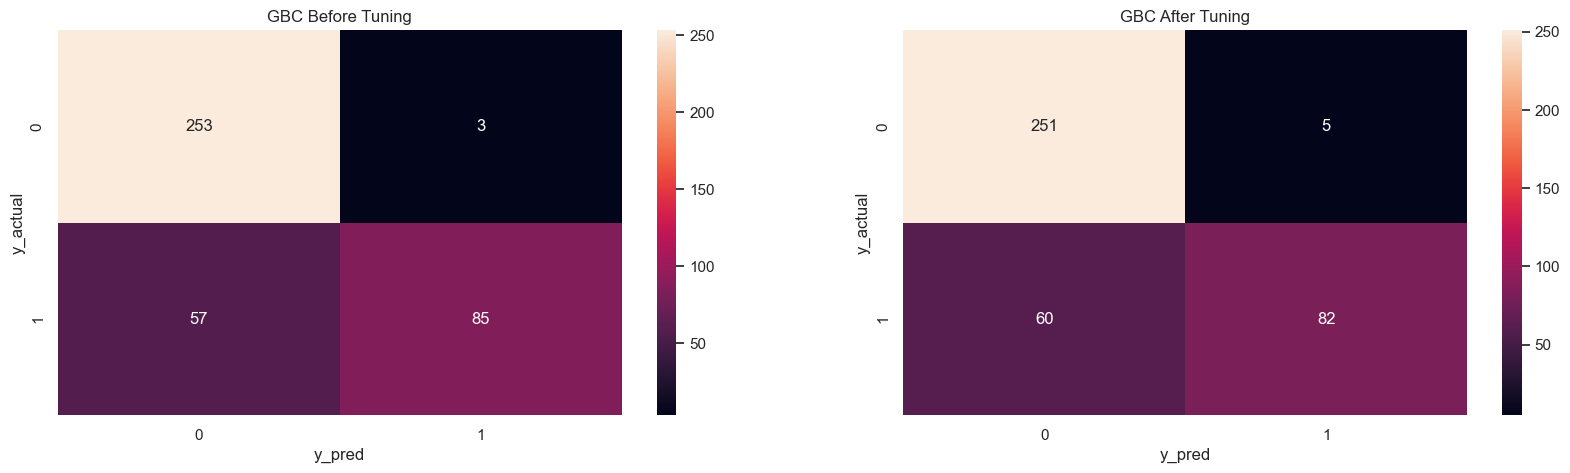

In [43]:
plt.figure(figsize=(20,5))

plt.subplot(1,2,1)
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='.0f')
plt.xlabel('y_pred')
plt.ylabel('y_actual')
plt.title('GBC Before Tuning')

plt.subplot(1,2,2)
sns.heatmap(confusion_matrix(y_test, y_pred_gbc_tuning), annot=True, fmt='.0f')
plt.xlabel('y_pred')
plt.ylabel('y_actual')
plt.title('GBC After Tuning')

**Best Model Score :** 
**GBC Before Tuning**

* TP : 85 
* TN : 253
* FP : 3
* FN : 57 

It shows the model are good in minimiazing the FP, but not really good on minimizing the FN.

## Before and After Hyperparameter Tuning : XGBC Model

In [44]:
benchmark_model

,testscore,trainscore,diff
model,,,
GradientBoostingClassifier,0.739130,0.705357,0.033774
AdaBoostClassifier,0.705357,0.660419,0.044938
DecisionTreeClassifier,0.696970,0.653198,0.043772
RandomForestClassifier,0.692308,0.677797,0.014511
XGBClassifier,0.682731,0.676672,0.006059
KNeighborsClassifier,0.674699,0.658455,0.016244
LogisticRegression,0.624473,0.595027,0.029445


In [46]:
# Before 
model = XGBClassifier(random_state=0, verbosity=0)

model_pipe_xgbc = Pipeline([
    ('transformer', transformer),
    ('model', model)
])

model_pipe_xgbc.fit(X_train, y_train)

y_pred = model_pipe_xgbc.predict(X_test)
f1_score(y_test, y_pred)

0.6827309236947791

In [47]:
# After 

xgbc_tuning = random_xgbc.best_estimator_

y_pred_xgbc_tuning = xgbc_tuning.predict(X_test)
print(classification_report(y_test, y_pred_xgbc_tuning))

              precision    recall  f1-score   support

           0       0.81      0.98      0.89       256
           1       0.93      0.60      0.73       142

    accuracy                           0.84       398
   macro avg       0.87      0.79      0.81       398
weighted avg       0.86      0.84      0.83       398



In [48]:
f1_score(y_test, y_pred_xgbc_tuning)

0.7296137339055793

Text(0.5, 1.0, 'XGBC After Tuning')

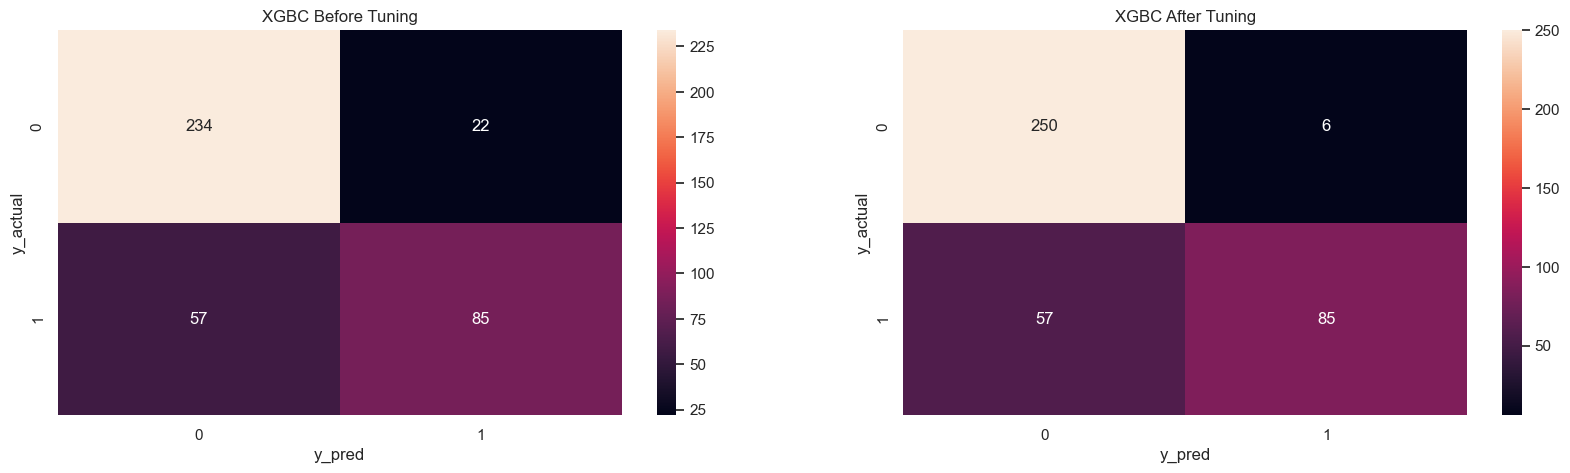

In [49]:
plt.figure(figsize=(20,5))

plt.subplot(1,2,1)
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='.0f')
plt.xlabel('y_pred')
plt.ylabel('y_actual')
plt.title('XGBC Before Tuning')

plt.subplot(1,2,2)
sns.heatmap(confusion_matrix(y_test, y_pred_xgbc_tuning), annot=True, fmt='.0f')
plt.xlabel('y_pred')
plt.ylabel('y_actual')
plt.title('XGBC After Tuning')

Best model remain 'Gradient Boosting before Hyperparameter Tuning' : XGBoost Tuning only hit 0.7296 F1 score. 

# Adjusting Threshold

In [53]:
# Predict Probabilities

model_threshold = model_pipe_gbc
# model_threshold = gbc_tuning
# model_threshold = xgbc_tuning

y_hat = model_threshold.predict_proba(X_test)

# -----------------------------------------

th_value = [i/100 for i in range(20,80)] 
score_list = []
score = 0

for i in th_value:
    # Predict
    y_prob = model_threshold.predict_proba(X_test)[:,1]
    y_pred = np.where(y_prob>i,1,0)

    score_temp = f1_score(y_test, y_pred)
    score_list.append(score_temp)

    if score_temp > score:
        score = score_temp

        best_score = score
        best_th = i 

print("Best F1 Score : ", best_score)
print("Best Threshold : ", best_th)

Best F1 Score :  0.7391304347826086
Best Threshold :  0.49


In [51]:
y_hat

array([[0.05243563, 0.94756437],
       [0.60077663, 0.39922337],
       [0.05581599, 0.94418401],
       [0.77822696, 0.22177304],
       [0.07410204, 0.92589796],
       [0.81613913, 0.18386087],
       [0.77459102, 0.22540898],
       [0.79813203, 0.20186797],
       [0.07495355, 0.92504645],
       [0.69635061, 0.30364939],
       [0.74318614, 0.25681386],
       [0.78366272, 0.21633728],
       [0.65271535, 0.34728465],
       [0.77254407, 0.22745593],
       [0.77486599, 0.22513401],
       [0.73170359, 0.26829641],
       [0.72663742, 0.27336258],
       [0.95363686, 0.04636314],
       [0.73799422, 0.26200578],
       [0.04944919, 0.95055081],
       [0.79423124, 0.20576876],
       [0.80986464, 0.19013536],
       [0.98156354, 0.01843646],
       [0.06396881, 0.93603119],
       [0.87177973, 0.12822027],
       [0.04944919, 0.95055081],
       [0.76403777, 0.23596223],
       [0.21103837, 0.78896163],
       [0.83640758, 0.16359242],
       [0.78335415, 0.21664585],
       [0.

In [54]:
# Predict Probabilities

# model_threshold = model_pipe_gbc
model_threshold = gbc_tuning
# model_threshold = xgbc_tuning

y_hat = model_threshold.predict_proba(X_test)

# -----------------------------------------

th_value = [i/100 for i in range(20,80)] 
score_list = []
score = 0

for i in th_value:
    # Predict
    y_prob = model_threshold.predict_proba(X_test)[:,1]
    y_pred = np.where(y_prob>i,1,0)

    score_temp = f1_score(y_test, y_pred)
    score_list.append(score_temp)

    if score_temp > score:
        score = score_temp

        best_score = score
        best_th = i 

print("Best F1 Score : ", best_score)
print("Best Threshold : ", best_th)

Best F1 Score :  0.7296137339055793
Best Threshold :  0.42


In [55]:
# Predict Probabilities

# model_threshold = model_pipe_gbc
# model_threshold = gbc_tuning
model_threshold = xgbc_tuning

y_hat = model_threshold.predict_proba(X_test)

# -----------------------------------------

th_value = [i/100 for i in range(20,80)] 
score_list = []
score = 0

for i in th_value:
    # Predict
    y_prob = model_threshold.predict_proba(X_test)[:,1]
    y_pred = np.where(y_prob>i,1,0)

    score_temp = f1_score(y_test, y_pred)
    score_list.append(score_temp)

    if score_temp > score:
        score = score_temp

        best_score = score
        best_th = i 

print("Best F1 Score : ", best_score)
print("Best Threshold : ", best_th)

Best F1 Score :  0.7391304347826086
Best Threshold :  0.69


After Adjusting threshold, the best model still in GBC before tuning, with best threshold in 0.49. 

# FINAL MODEL

In [56]:
# Best Model 
model_final = model_pipe_gbc 

# Predict 
y_prob = model_final.predict(X_test)
y_pred = np.where(y_prob>0.49,1,0)

In [58]:
# Feature importance

model_final

Pipeline(steps=[('transformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehot', OneHotEncoder(),
                                                  ['Employment Type',
                                                   'GraduateOrNot',
                                                   'FrequentFlyer',
                                                   'EverTravelledAbroad'])])),
                ('model', GradientBoostingClassifier(random_state=0))])

In [59]:
# transformer
model_final[0].transform(X_train)

array([[1.00e+00, 0.00e+00, 0.00e+00, ..., 4.00e+05, 5.00e+00, 1.00e+00],
       [1.00e+00, 0.00e+00, 0.00e+00, ..., 1.05e+06, 7.00e+00, 0.00e+00],
       [0.00e+00, 1.00e+00, 0.00e+00, ..., 1.40e+06, 7.00e+00, 0.00e+00],
       ...,
       [0.00e+00, 1.00e+00, 0.00e+00, ..., 8.00e+05, 6.00e+00, 0.00e+00],
       [1.00e+00, 0.00e+00, 0.00e+00, ..., 6.00e+05, 5.00e+00, 0.00e+00],
       [0.00e+00, 1.00e+00, 0.00e+00, ..., 1.05e+06, 8.00e+00, 0.00e+00]])

In [60]:
model_final[1].predict(X_train)

ValueError: could not convert string to float: 'Government Sector'

In [61]:
model_final[0].transform(X_train).shape

(1589, 12)

In [63]:
features = list(transformer.get_feature_names_out())
features

['onehot__Employment Type_Government Sector',
 'onehot__Employment Type_Private Sector/Self Employed',
 'onehot__GraduateOrNot_No',
 'onehot__GraduateOrNot_Yes',
 'onehot__FrequentFlyer_No',
 'onehot__FrequentFlyer_Yes',
 'onehot__EverTravelledAbroad_No',
 'onehot__EverTravelledAbroad_Yes',
 'remainder__Age',
 'remainder__AnnualIncome',
 'remainder__FamilyMembers',
 'remainder__ChronicDiseases']

In [64]:
features = list(transformer.get_feature_names_out())

list_features = []

for feature in features:
    list_features.append('_'.join(feature.split('_')[2:]))
list_features

['Employment Type_Government Sector',
 'Employment Type_Private Sector/Self Employed',
 'GraduateOrNot_No',
 'GraduateOrNot_Yes',
 'FrequentFlyer_No',
 'FrequentFlyer_Yes',
 'EverTravelledAbroad_No',
 'EverTravelledAbroad_Yes',
 'Age',
 'AnnualIncome',
 'FamilyMembers',
 'ChronicDiseases']

In [65]:
imp = model_final[-1].feature_importances_
imp

array([0.00350116, 0.00391385, 0.00473123, 0.00718107, 0.00370474,
       0.00699451, 0.00180246, 0.00210722, 0.10566222, 0.63575807,
       0.20453002, 0.02011344])

In [66]:
# To Dataframe

feature_imp = pd.DataFrame({
    'Importance' : imp,
    'Feature' : list_features
}).sort_values(by='Importance', ascending=False)
feature_imp

,Importance,Feature
9,0.635758,AnnualIncome
10,0.204530,FamilyMembers
8,0.105662,Age
11,0.020113,ChronicDiseases
3,0.007181,GraduateOrNot_Yes
5,0.006995,FrequentFlyer_Yes
2,0.004731,GraduateOrNot_No
1,0.003914,Employment Type_Private Sector/Self Employed
4,0.003705,FrequentFlyer_No
0,0.003501,Employment Type_Government Sector


<Axes: xlabel='Importance', ylabel='Feature'>

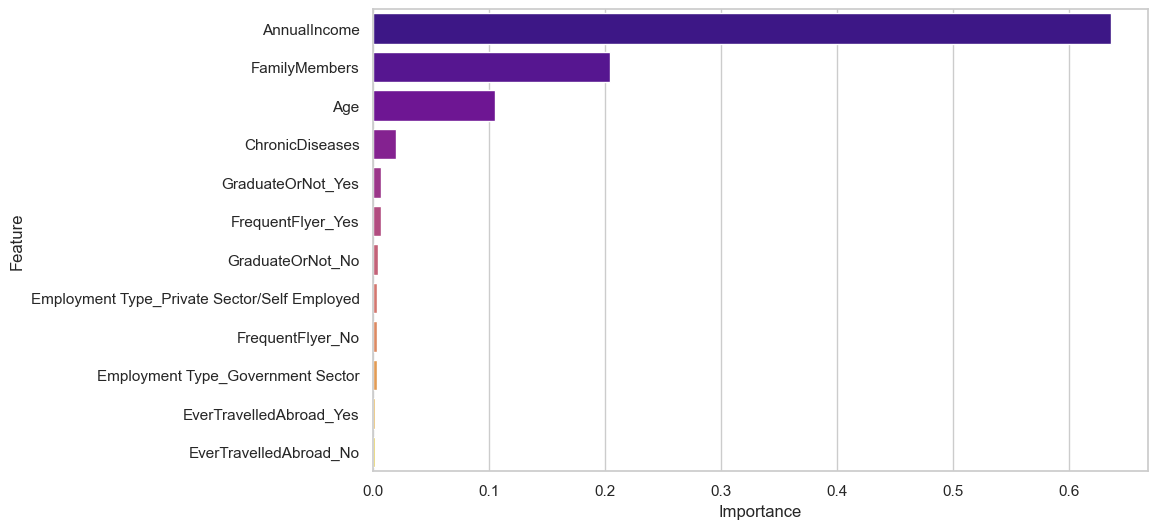

In [70]:
# Visualization 

plt.figure(figsize=(10,6))
sns.set_theme(style="whitegrid")
sns.barplot(data=feature_imp, x='Importance', y='Feature', orient='h', palette='plasma')

# Save Model

In [72]:
# Save the model 

import pickle

model_final = model_pipe_gbc
model_final.fit(X_train, y_train)

pickle.dump(model_final, open('MODULE 3 - MACHINE LEARNING.sav', 'wb'))


In [73]:
model_final[1].predict

<bound method GradientBoostingClassifier.predict of GradientBoostingClassifier(random_state=0)>

# EXPLANABLE AI

In [74]:
import shap

In [75]:
# Explainer 

explainer = shap.Explainer(
    model_final[1].predict,
    model_final[0].transform(X_test)
)

shap_values = explainer(model_final[0].transform(X_test))

Permutation explainer: 399it [00:37,  9.47it/s]                         


In [76]:
# SHAP VALUES to explain observation in test 

X_test.iloc[0]

Age                                              25
Employment Type        Private Sector/Self Employed
GraduateOrNot                                   Yes
AnnualIncome                                1400000
FamilyMembers                                     5
ChronicDiseases                                   0
FrequentFlyer                                    No
EverTravelledAbroad                             Yes
Name: 1926, dtype: object

In [77]:
X_test.iloc[0], y_test.iloc[0]

(Age                                              25
 Employment Type        Private Sector/Self Employed
 GraduateOrNot                                   Yes
 AnnualIncome                                1400000
 FamilyMembers                                     5
 ChronicDiseases                                   0
 FrequentFlyer                                    No
 EverTravelledAbroad                             Yes
 Name: 1926, dtype: object,
 1)

In [80]:
[i for i in enumerate(list_features)]

[(0, 'Employment Type_Government Sector'),
 (1, 'Employment Type_Private Sector/Self Employed'),
 (2, 'GraduateOrNot_No'),
 (3, 'GraduateOrNot_Yes'),
 (4, 'FrequentFlyer_No'),
 (5, 'FrequentFlyer_Yes'),
 (6, 'EverTravelledAbroad_No'),
 (7, 'EverTravelledAbroad_Yes'),
 (8, 'Age'),
 (9, 'AnnualIncome'),
 (10, 'FamilyMembers'),
 (11, 'ChronicDiseases')]

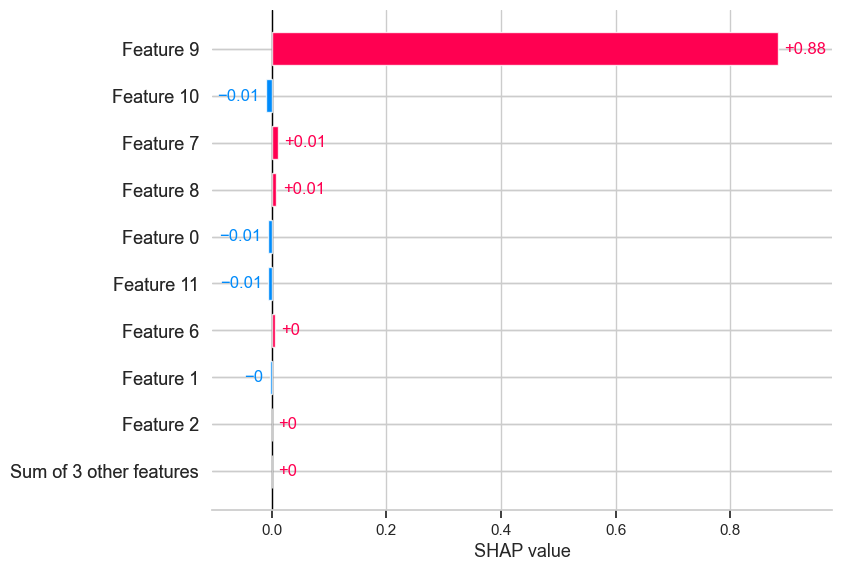

In [78]:
shap.plots.bar(shap_values[0])

In [81]:
# Shap values to explain all features in train
X_train_trans = model_final[0].transform(X_train)

# Explianer
explainer = shap.TreeExplainer(
    model_final.named_steps['model'],
    data = X_train_trans,
    feature_perturbation= 'interventional',
    model_output= 'probability'
)

# Shap values 
shap_values = explainer.shap_values(X_train_trans)

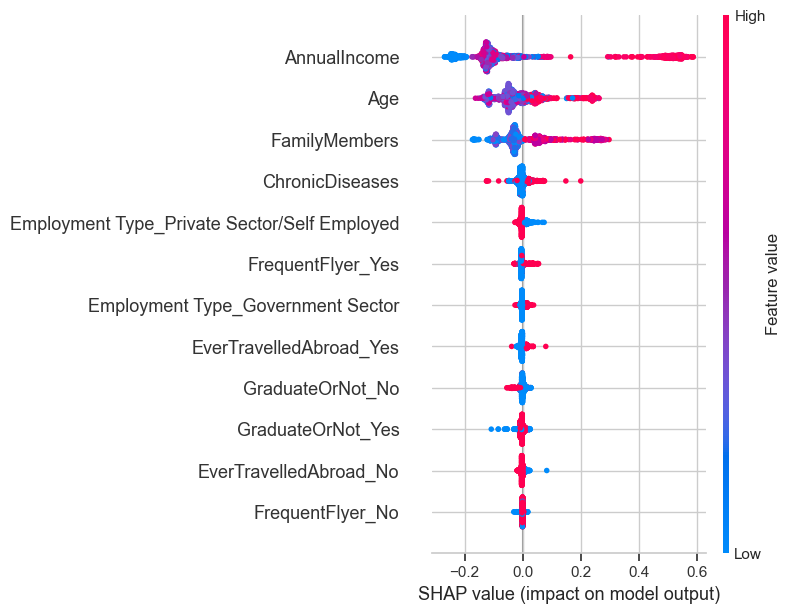

In [83]:
# Summary Plot for Model in Train 

shap.summary_plot(
    shap_values,
    X_train_trans,
    feature_names = list_features
)

In [84]:
def shap_plot(idx, model, dataset):
    explainerModel = shap.TreeExplainer(model)
    shap_values_model = explainerModel.shap_values(dataset)
    p = shap.force_plot(explainerModel.expected_value, shap_values_model[idx], dataset.iloc[[idx]])
    return (p)

In [86]:
X_test.iloc[0], y_test.iloc[0]

(Age                                              25
 Employment Type        Private Sector/Self Employed
 GraduateOrNot                                   Yes
 AnnualIncome                                1400000
 FamilyMembers                                     5
 ChronicDiseases                                   0
 FrequentFlyer                                    No
 EverTravelledAbroad                             Yes
 Name: 1926, dtype: object,
 1)

In [87]:
X_test_preprocessed = pd.DataFrame(model_final[0].transform(X_test))
X_test_preprocessed.columns = list_features
X_test_preprocessed

,Employment Type_Government Sector,Employment Type_Private Sector/Self Employed,GraduateOrNot_No,GraduateOrNot_Yes,FrequentFlyer_No,FrequentFlyer_Yes,EverTravelledAbroad_No,EverTravelledAbroad_Yes,Age,AnnualIncome,FamilyMembers,ChronicDiseases
0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,25.0,1400000.0,5.0,0.0
1,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,26.0,500000.0,9.0,0.0
2,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,34.0,1500000.0,6.0,1.0
3,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,25.0,1150000.0,4.0,0.0
4,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,31.0,1400000.0,6.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
393,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,34.0,700000.0,6.0,0.0
394,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,34.0,1500000.0,4.0,0.0
395,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,34.0,700000.0,4.0,0.0
396,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,34.0,1300000.0,5.0,0.0


In [88]:
shap.initjs()

In [90]:
i = 1

print(f"The prediction for this customer is : {('Buy' if y_test.iloc[i] == 1 else 'Do not Buy')} --> from y_test")

shap_plot(i, model_final['model'], X_test_preprocessed)
      

The prediction for this customer is : Do not Buy --> from y_test


In [92]:
pip install line


  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for line: filename=line-0.8.2-py3-none-any.whl size=13133 sha256=0eb93d050f2c0d26b7cbfeb845bc1779f208017a7336bc3feae04ec8190ee61e
  Stored in directory: c:\users\myasu\appdata\local\pip\cache\wheels\eb\ae\47\b9741394f80f1609051e02342eb16010d476ca844842581bb3
Successfully built line


In [96]:
pip install lime

     ---------------------------------------- 0.0/275.7 kB ? eta -:--:--
     - -------------------------------------- 10.2/275.7 kB ? eta -:--:--
     ---- -------------------------------- 30.7/275.7 kB 325.1 kB/s eta 0:00:01
     ---- -------------------------------- 30.7/275.7 kB 325.1 kB/s eta 0:00:01
     ----- ------------------------------- 41.0/275.7 kB 217.9 kB/s eta 0:00:02
     -------- ---------------------------- 61.4/275.7 kB 297.7 kB/s eta 0:00:01
     --------- --------------------------- 71.7/275.7 kB 245.8 kB/s eta 0:00:01
     -------------- --------------------- 112.6/275.7 kB 344.8 kB/s eta 0:00:01
     ---------------- ------------------- 122.9/275.7 kB 342.4 kB/s eta 0:00:01
     ---------------- ------------------- 122.9/275.7 kB 342.4 kB/s eta 0:00:01
     ------------------ ----------------- 143.4/275.7 kB 293.2 kB/s eta 0:00:01
     ------------------------- ---------- 194.6/275.7 kB 368.6 kB/s eta 0:00:01
     ----------------------------- ------ 225.3/275.7

In [97]:
import lime
from lime import lime_tabular

In [101]:
explainer = lime_tabular.LimeTabularExplainer(
    training_data = model_final[0].transform(X_train),
    feature_names = list_features,
    class_names = ['Not Buy', 'Buy'],
    mode = 'classification'
)

explainer

The prediction for this customer is : Do not Buy --> from y_test


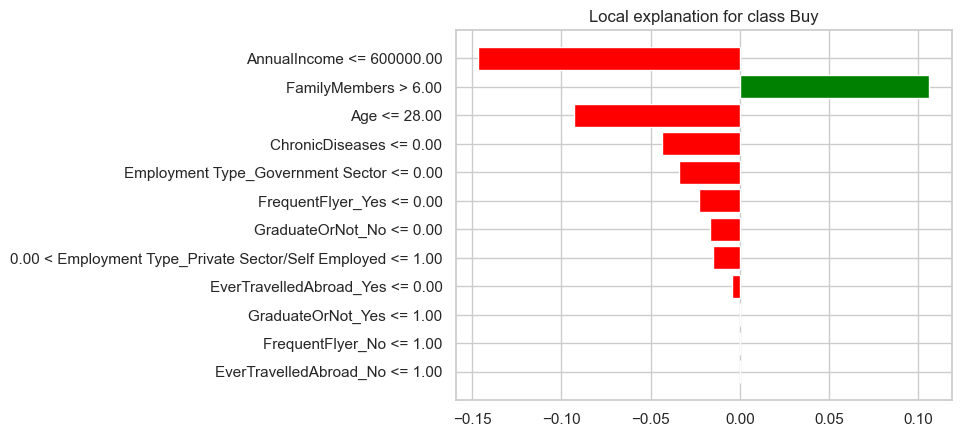

In [107]:
i = 1

print(f"The prediction for this customer is : {('Buy' if y_test.iloc[i] == 1 else 'Do not Buy')} --> from y_test")

exp = explainer.explain_instance(
    X_test_preprocessed.iloc[i],
    model_final['model'].predict_proba,
    num_features = 12
)

exp.as_pyplot_figure()
plt.show()

In [105]:
i = 1

print(f"The prediction for this customer is : {('Buy' if y_test.iloc[i] == 1 else 'Do not Buy')} --> from y_test")

exp = explainer.explain_instance(
    X_test_preprocessed.iloc[i],
    model_final['model'].predict_proba
)

exp.show_in_notebook(show_table=True)
plt.show()

The prediction for this customer is : Do not Buy --> from y_test
